# Lecture 14 notebook: how the price moves

This notebook replays Lecture 14 on the tape of Lecture 12 and the bars of Lecture 13. Every figure and number of the lecture comes from a
script in `scripts/`, next to this notebook; each runs in a fresh process, so that memory is freed after every step.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | What a candle loses | §2 |
| 2 | The path against a random walk: the shuffled benchmark, two regimes, the variance ratio | §3 |
| 3 | Levels on the path: crossings, excursions, gaps and stop fills | §4 |
| 4 | Volatility built up: construction, precision, interval, forecasting with honest yardsticks, jumps | §5 |
| 5 | Risk on any clock and the duration measure | §6 |
| 6 | A test of your own | §8.2 |

**Before you start.** Lecture 12's notebook must have built the tape, and Lecture 13's notebook the bars, for October 2021 to September 2026.
Results go to `data/interim/l14`; figures are saved in `figures/` as `nb_*`, so the lecture's own figures are never overwritten.

## 0. Settings

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, Markdown, display

HERE = Path.cwd()
SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS), str(HERE.parent / "13-bars-not-cut-by-time" / "scripts"), str(HERE.parent / "12-tick-data-the-tape"), str(HERE.parents[1])]
import tape
OUT = tape.ROOT / "interim" / "l14"

RUN_HEAVY = False      # §3: gap and stop-fill measurements read 300 days of trades: about 30 minutes, hours when free memory is short; False shows an earlier run

pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200)
print("data folder:", "the folder in the environment variable TAPE_ROOT" if os.environ.get("TAPE_ROOT") else "data/ at the top of the repository")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, show=False):
    """Run a script of scripts/ in a fresh process; figures to figures/ as nb_*, results to data/interim/l14."""
    t0 = time.time()
    env = {**os.environ, "TAPE_ROOT": str(tape.ROOT), "L14_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def result(name):
    return json.loads((OUT / name).read_text(encoding="utf-8"))


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)

data folder: the folder in the environment variable TAPE_ROOT
free memory: 1.8 GB of 16.9 GB


## 1. What a candle loses

Lecture §2: which came first, the high or the low, and how often two common guesses get it right, on the tape and on a random walk; a stop and a
target at the same distance; and how far an hour travels compared with its range.

In [2]:
run("l14_s2.py")
s2 = result("l14_s2.json")
display(pl.DataFrame([{"bar": k, **v} for k, v in s2["order"].items()]))
display(Markdown(f"**A random walk:** {s2['random_walk']}"))
display(pl.DataFrame([{"stop and target, x typical hourly range": float(k), **v} for k, v in s2["stop_target"].items()]))
s2["path_over_range"]

l14_s2.py: 3 s


bar,bars,direction_rule,open_nearer
str,i64,f64,f64
"""5 min""",504534,0.896,0.807
"""1 hour""",43799,0.879,0.795
"""1 day""",1820,0.879,0.805


**A random walk:** {'direction_rule': 0.887, 'open_nearer': 0.808}

"stop and target, x typical hourly range",touch_both,direction_right
f64,f64,f64
0.25,0.396,0.681
0.5,0.131,0.76
1.0,0.022,0.802


{'median': 3.9, 'same_range_p10': 3.0, 'same_range_p90': 5.3}

## 2. The path against a random walk

Lecture §3. Steps of 10 to 500 bp on one-minute prices; the share that continue, on the tape and on its own returns shuffled; by year; for days
grouped by their volatility; and the variance ratio from five minutes to a week. Then the lecture's figures 14_01 to 14_03.

l14_steps.py: 2 s


l14_path_tests.py: 4 s


l14_regimes.py: 3 s


l14_s23_charts.py: 9 s


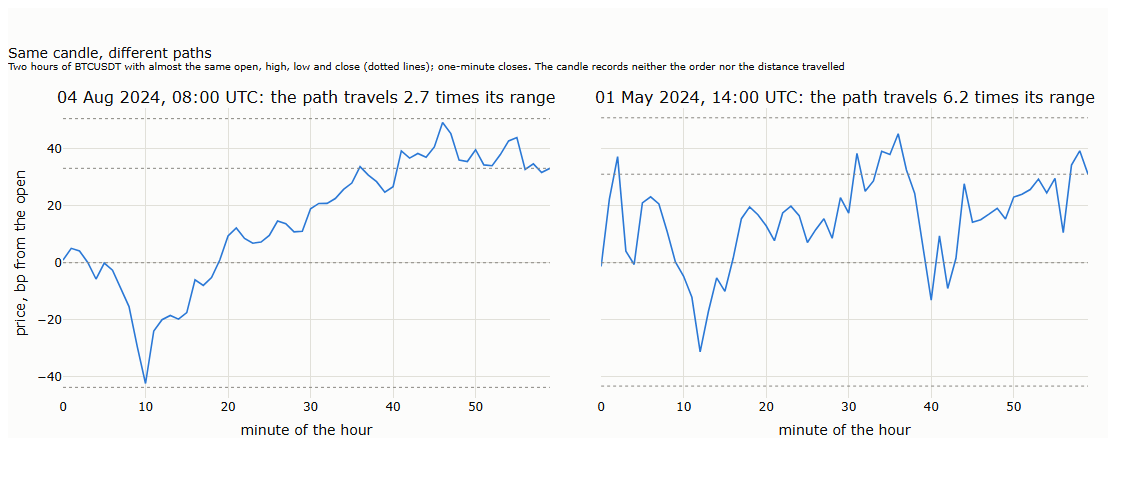

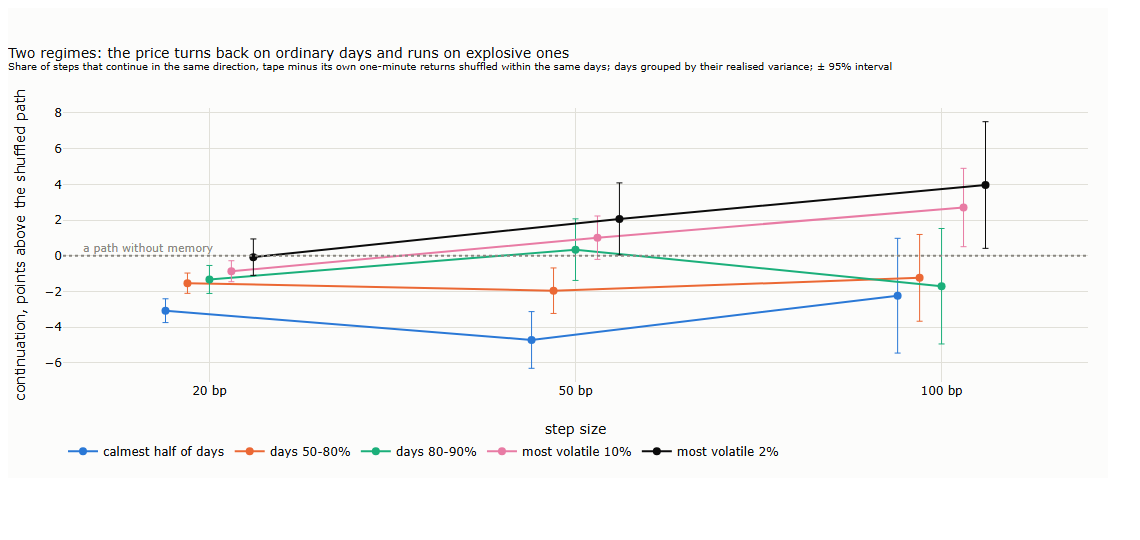

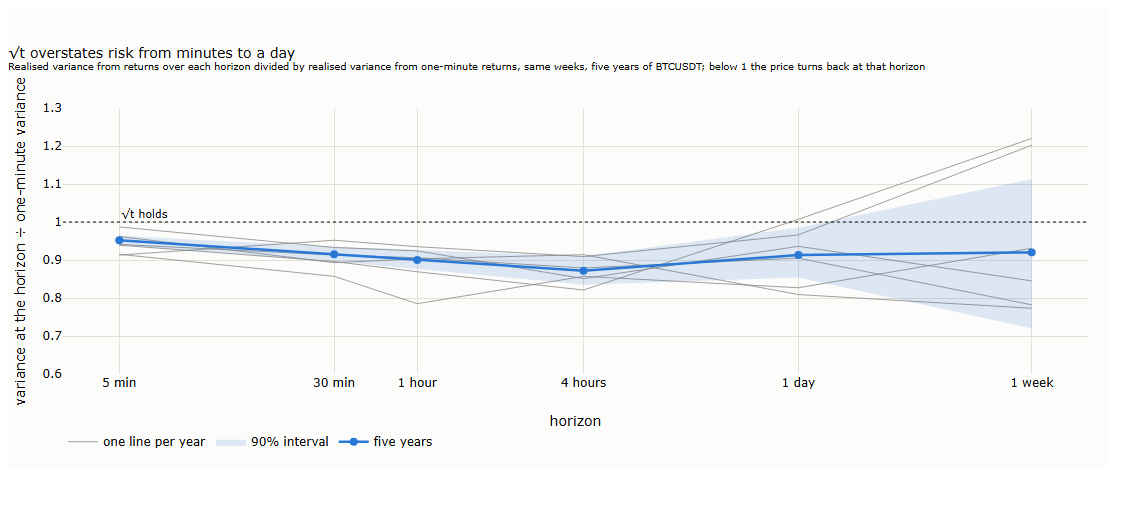

**Continuation, tape minus shuffled, points, by year**

"step, bp",2021,2022,2023,2024,2025,2026
i64,f64,f64,f64,f64,f64,f64
10,-2.4,-2.04,-2.32,-1.61,-1.78,-1.9
20,-1.6,-1.22,-1.61,-1.29,-1.34,-1.58
50,-1.93,-0.88,-0.16,-0.42,-0.4,-1.84
100,-0.32,1.95,-0.72,-1.24,0.94,-0.41


**Variance ratio**

horizon,ratio,90% interval
str,f64,str
"""5 min""",0.952,"""[0.939, 0.964]"""
"""30 min""",0.915,"""[0.897, 0.935]"""
"""1 hour""",0.9,"""[0.877, 0.926]"""
"""4 hours""",0.872,"""[0.835, 0.91]"""
"""1 day""",0.913,"""[0.854, 0.985]"""
"""1 week""",0.92,"""[0.72, 1.113]"""


**Two regimes: days grouped by the same day's and by the previous day's volatility**

grouped by,days,vr_30m,vr_60m,vr_240m,step_20bp_pts,step_50bp_pts,step_100bp_pts
str,i64,f64,f64,f64,f64,f64,f64
"""same day""",913,0.843,0.794,0.617,-3.08,-4.72,-2.24
"""same day""",548,0.902,0.892,0.749,-1.54,-1.96,-1.24
"""same day""",183,0.92,0.924,0.824,-1.33,0.34,-1.71
"""same day""",183,0.926,0.875,0.75,-0.87,1.01,2.7
"""same day""",37,0.885,0.803,0.583,-0.08,2.06,3.96
"""previous day""",913,0.955,0.929,0.766,-0.77,-0.63,3.23
"""previous day""",548,0.897,0.878,0.78,-1.33,0.29,-0.09
"""previous day""",182,0.856,0.843,0.746,-0.69,0.53,0.25
"""previous day""",183,0.883,0.821,0.645,-1.44,-2.59,-2.48


In [3]:
run("l14_steps.py"); run("l14_path_tests.py"); run("l14_regimes.py"); run("l14_s23_charts.py")
pictures("14_01_same_candle_different_paths", "14_02_two_regimes", "14_03_variance_ratio")
pt = result("l14_path_tests.json")
display(Markdown("**Continuation, tape minus shuffled, points, by year**"))
display(pl.DataFrame([{"step, bp": int(k), **{str(y): v["diff_pts"] for y, v in row.items()}} for k, row in pt["steps"].items()]))
display(Markdown("**Variance ratio**"))
display(pl.DataFrame([{"horizon": k, "ratio": v["ratio"], "90% interval": str(v["ci90"])} for k, v in pt["variance_ratio"].items()]))
display(Markdown("**Two regimes: days grouped by the same day's and by the previous day's volatility**"))
reg = result("l14_regimes.json")
pl.DataFrame([{"grouped by": b, "days": g, **v} for b, rows in reg.items() for g, v in rows.items()])

## 3. Levels on the path

Lecture §4: crossings against the random-walk count, excursions against the random walk, and what the sellers who followed a stop's trigger got,
within 0.1 to 10 seconds. The gap and stop-fill measurements read the trades of 300 days (set `RUN_HEAVY = True` in §0 to rerun them).

l14_s4.py: 9 s


l14_s4_charts.py: 8 s


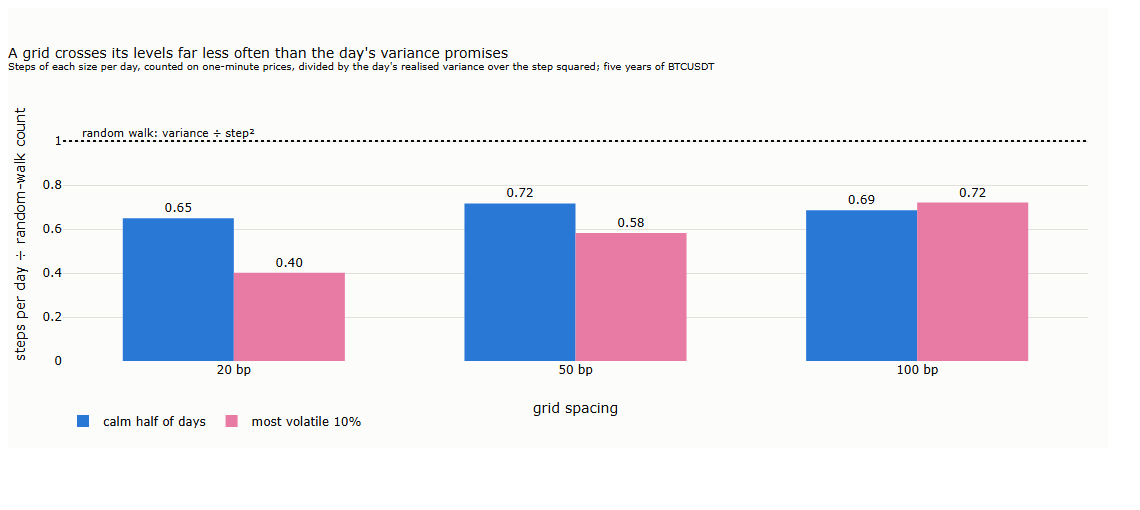

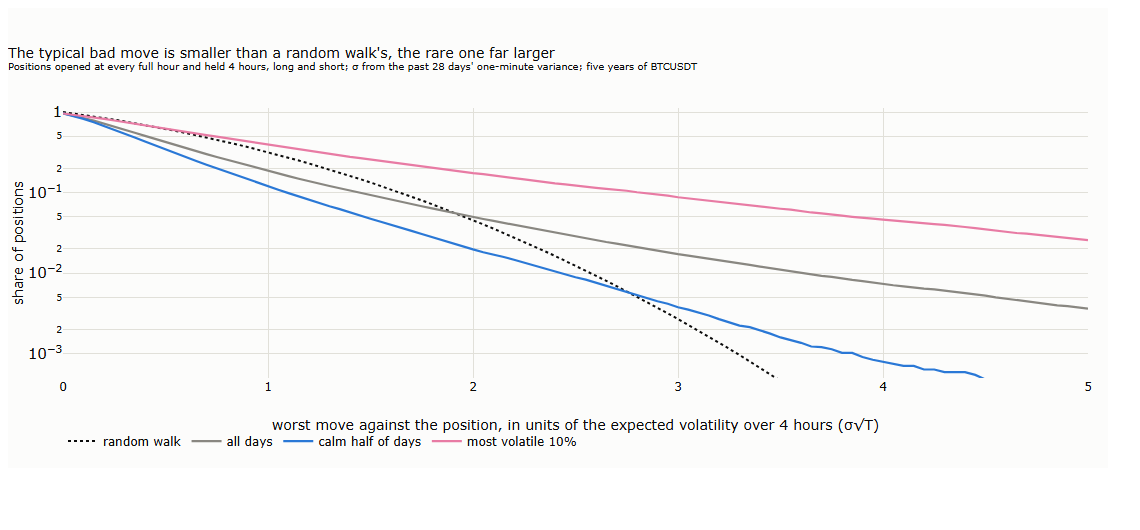

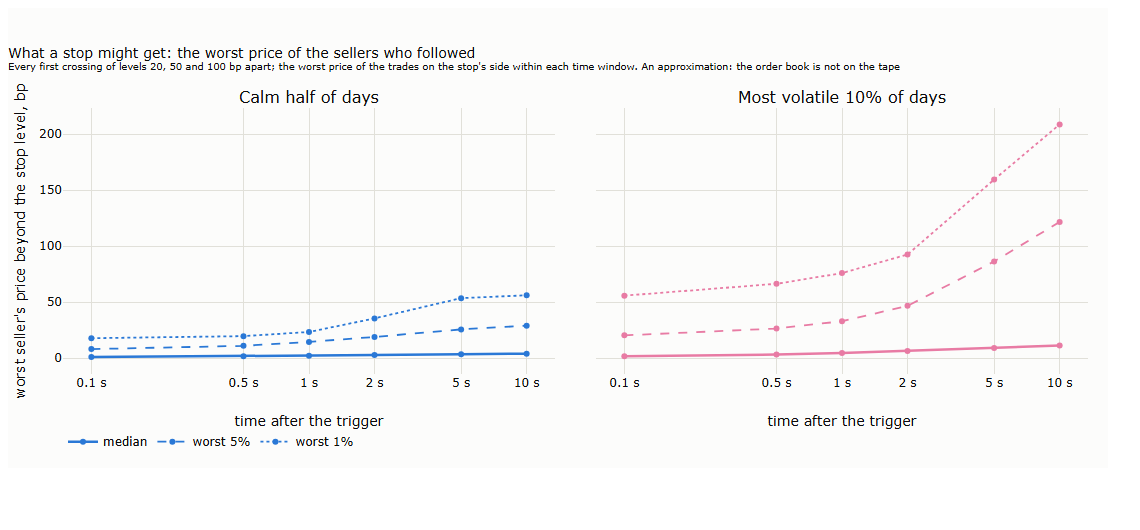

"step, bp",days,steps_per_day,random_walk,ratio,turns_per_day,turn_share
i64,str,f64,f64,f64,f64,f64
20,"""calm half""",46.4,71.4,0.649,20.2,0.444
20,"""most volatile 10%""",303.3,756.2,0.401,97.8,0.324
20,"""all days""",103.1,198.8,0.518,39.4,0.386
50,"""calm half""",8.2,11.4,0.716,3.6,0.498
50,"""most volatile 10%""",70.5,121.0,0.582,26.6,0.382
50,"""all days""",21.0,31.8,0.661,8.6,0.429
100,"""calm half""",2.0,2.9,0.685,0.6,0.646
100,"""most volatile 10%""",21.8,30.2,0.72,8.3,0.401
100,"""all days""",5.9,8.0,0.738,2.2,0.449


held,days,mean,p_over_2,p_over_3
str,str,f64,f64,f64
"""1 hour""","""calm half""",0.46,0.0205,0.0051
"""1 hour""","""most volatile 10%""",1.08,0.1451,0.0714
"""1 hour""","""all""",0.59,0.0439,0.0162
"""1 hour""","""random walk""",0.8,0.0455,0.0027
"""4 hours""","""calm half""",0.48,0.0197,0.0038
"""4 hours""","""most volatile 10%""",1.2,0.1748,0.0876
"""4 hours""","""all""",0.64,0.0497,0.0173
"""4 hours""","""random walk""",0.8,0.0455,0.0027
"""1 day""","""calm half""",0.56,0.0266,0.0045


**Gaps at the trigger and resting orders traded through**

days,"step, bp",levels,gap_median_bp,gap_p90,gap_p99,gap_over_10bp,vwap1m_median,vwap1m_p90,vwap1m_p99,vwap1m_p999,vwap1m_max,gap_p999,gap_max,through,at_only,wrong_side_only
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""calm""",20,1332,0.0,0.03,0.1,0.0,0.38,1.0,2.0,2.6,2.9,0.1,0.1,0.999,0.001,0.0
"""calm""",50,459,0.0,0.02,0.0,0.0,0.38,1.0,1.6,2.6,2.6,0.1,0.1,1.0,0.0,0.0
"""calm""",100,182,0.0,0.02,0.0,0.0,0.4,0.9,1.7,2.4,2.6,0.1,0.1,1.0,0.0,0.0
"""volatile""",20,8137,0.0,0.06,0.2,0.0,0.68,2.3,5.3,12.5,19.5,0.5,1.1,0.997,0.003,0.0
"""volatile""",50,3160,0.0,0.06,0.2,0.0,0.66,2.2,5.7,13.1,19.5,0.5,0.9,1.0,0.0,0.0
"""volatile""",100,1496,0.0,0.06,0.2,0.0,0.62,2.1,5.7,16.1,19.5,0.5,0.6,1.0,0.0,0.0


In [4]:
run("l14_s4.py")
if RUN_HEAVY:
    run("l14_gaps.py"); run("l14_stopfan.py")
run("l14_s4_charts.py")
pictures("14_04_crossings", "14_05_excursions", "14_06_stop_fills")
s4 = result("l14_s4.json")
display(pl.DataFrame([{"step, bp": int(k), "days": d, **v} for k, rows in s4["crossings"].items() for d, v in rows.items()]))
display(pl.DataFrame([{"held": h, "days": d, **v} for h, rows in s4["excursions"].items() for d, v in rows.items()]))
if (OUT / "l14_gaps.json").exists():
    display(Markdown("**Gaps at the trigger and resting orders traded through**"))
    display(pl.DataFrame([{"days": lab, "step, bp": int(bp), **v} for lab, rows in result("l14_gaps.json").items() for bp, v in rows.items()]))

## 4. Volatility built up

Lecture §5: each estimator built through an ordinary day and the Fed day; their precision over five years; the signatures of realised variance,
bipower and the range from one second to an hour; trades in jump minutes; and the forecasting test against three yardsticks built differently.

l14_signatures.py: 21 s


l14_s5.py: 6 s


l14_jump_trades.py: 1 s


l14_forecast.py: 4 s


l14_forecast.py: 3 s


l14_forecast.py: 3 s


l14_forecast_chart.py: 3 s


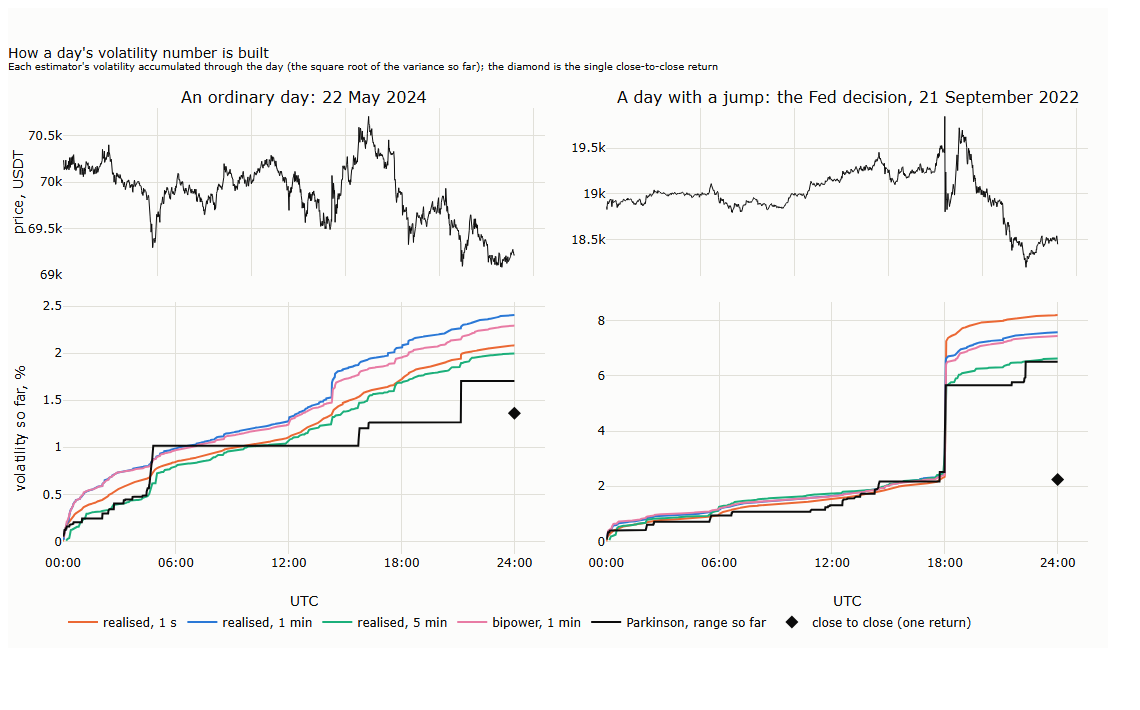

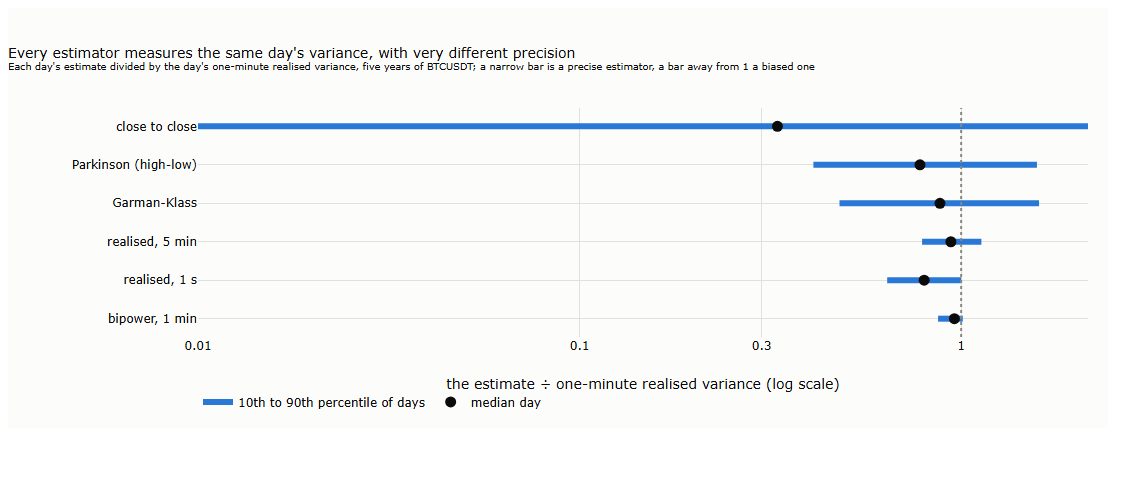

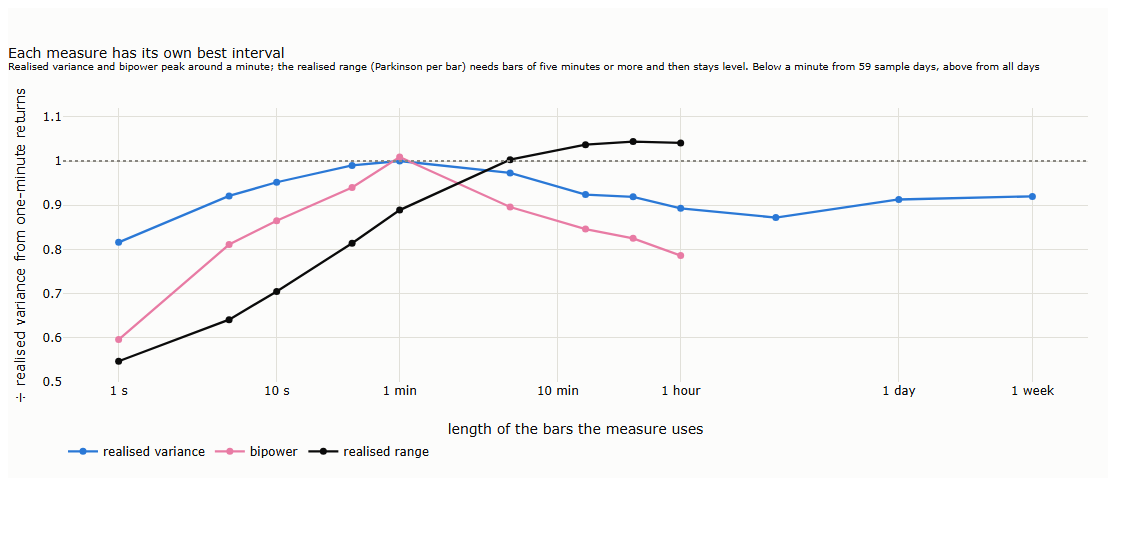

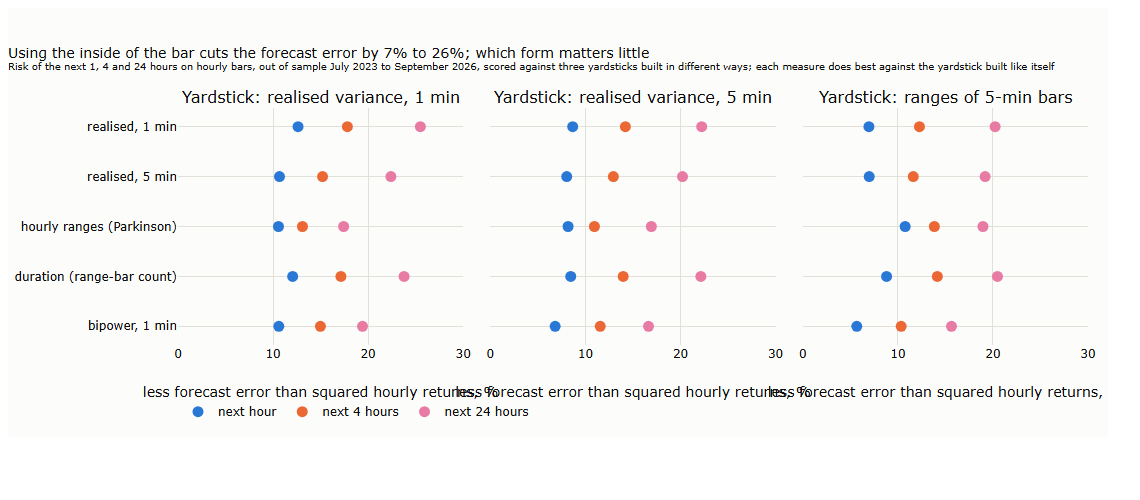

estimator,median,p10,p90
str,f64,f64,f64
"""close to close""",0.33,0.01,2.15
"""Parkinson (high-low)""",0.78,0.41,1.58
"""Garman-Klass""",0.88,0.48,1.6
"""realised, 5 min""",0.94,0.79,1.13
"""realised, 1 s""",0.8,0.64,1.0
"""bipower, 1 min""",0.96,0.87,1.01


**Busiest 1% of minutes, share of a day's variance:** {'median': 0.214, 'p90': 0.371}; **jump share:** {'median': 0.044, 'p90': 0.132, 'mean': 0.058}

**Trades in jump minutes**

minutes,trades_vs_median,share_fewer_trades,dollars_vs_median
i64,f64,f64,f64
1881963,0.9,0.574,0.9
153156,1.8,0.144,2.5
16504,4.3,0.017,8.0
1980,13.9,0.005,29.0


In [5]:
run("l14_signatures.py"); run("l14_s5.py"); run("l14_jump_trades.py")
for target in ("realised, 1 min", "realised, 5 min", "range of 5-min bars"):
    run("l14_forecast.py", target)
run("l14_forecast_chart.py")
pictures("14_07_volatility_built_up", "14_09_estimators_five_years", "14_08_interval", "14_10_forecasts")
s5 = result("l14_s5.json")
display(pl.DataFrame([{"estimator": k, **v} for k, v in s5["vs_rv1m"].items()]))
display(Markdown(f"**Busiest 1% of minutes, share of a day's variance:** {s5['top1pct_share']}; **jump share:** {s5['jump_share']}"))
display(Markdown("**Trades in jump minutes**"))
pl.DataFrame([{"minutes": k, **v} for k, v in result("l14_jump_trades.json").items()])

## 5. Risk on any clock and the duration measure

Lecture §6: where each clock puts a day's risk, Wald's identity, precision by clock; the duration measure's bias by sampling interval and bar
count, taken apart by simulation, and corrected.

l14_s6.py: 6 s


l14_duration_bias.py: 10 s


l14_duration_sim.py: 8 s


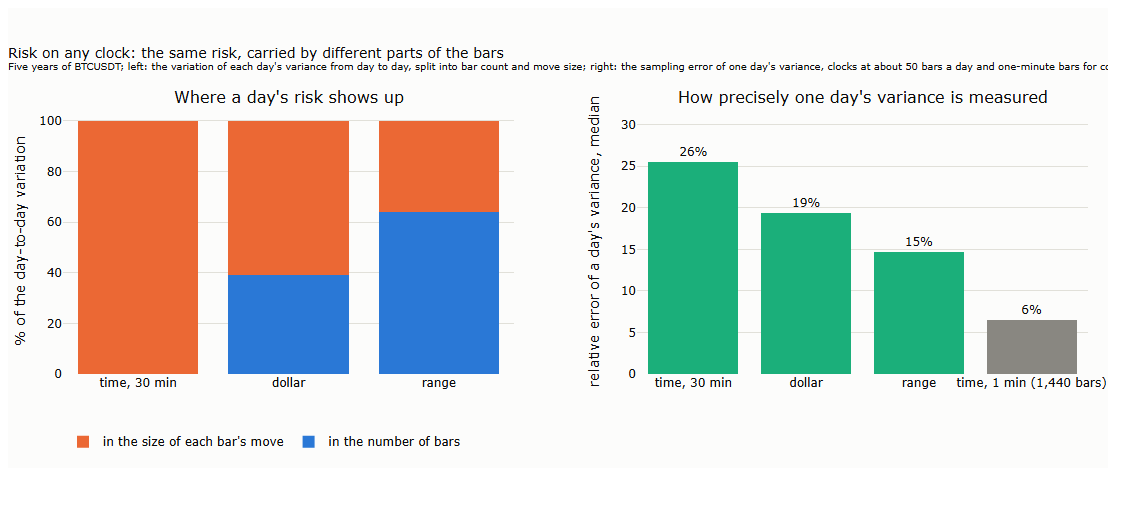

clock,bars_per_day,share_count,share_size,corr,true_over_product,rel_error,rel_error_normal
str,f64,f64,f64,f64,f64,f64,f64
"""time, 30 min""",48.0,-0.0,1.0,-0.02,1.0,0.255,0.204
"""tick""",53.3,0.389,0.612,0.45,1.159,0.206,0.194
"""dollar""",51.7,0.391,0.609,0.42,1.145,0.194,0.197
"""range""",60.5,0.64,0.36,-0.05,0.973,0.147,0.182
"""CUSUM""",60.5,0.642,0.358,-0.06,0.967,0.146,0.182
"""time, 1 min""",1439.9,null,null,null,null,0.065,0.037


**Duration measure ÷ realised variance, by sampling interval and bars a day**

setting,ratio
str,f64
"""0.1 s, 12 bars/day""",0.958
"""0.1 s, 48 bars/day""",0.927
"""0.1 s, 192 bars/day""",0.82
"""1 s, 12 bars/day""",0.875
"""1 s, 48 bars/day""",0.865
"""1 s, 192 bars/day""",0.745
"""5 s, 12 bars/day""",0.833
"""5 s, 48 bars/day""",0.75
"""5 s, 192 bars/day""",0.628


**Simulation, features added one at a time**

market,ratio
str,f64
"""a random walk""",0.92
"""+ busy and quiet hours""",0.938
"""+ fat-tailed moves""",0.915
"""+ turning back over minutes, averaged price""",0.828


{'raw_median': 0.864,
 'raw_p10': 0.71,
 'raw_p90': 0.99,
 'corrected_median': 0.913,
 'corrected_by_year': {'2021': 0.94,
  '2022': 0.925,
  '2023': 0.914,
  '2024': 0.903,
  '2025': 0.91,
  '2026': 0.883}}

In [6]:
run("l14_s6.py"); run("l14_duration_bias.py"); run("l14_duration_sim.py")
pictures("14_11_risk_on_any_clock")
display(pl.DataFrame([{"clock": k, **v} for k, v in result("l14_s6.json").items()]))
display(Markdown("**Duration measure ÷ realised variance, by sampling interval and bars a day**"))
display(pl.DataFrame([{"setting": k, "ratio": v} for k, v in result("l14_duration_bias.json").items()]))
ds = result("l14_duration_sim.json")
display(Markdown("**Simulation, features added one at a time**")); display(pl.DataFrame([{"market": k, "ratio": v} for k, v in ds["simulation"].items()]))
ds["tape"]

## 6. A test of your own

The step test of §3 on any market whose one-minute bars Lecture 12's pipeline has built, for example SOLUSDT or ETHUSDT (exercise 1 of §8.2).
It compares the tape with its own shuffled returns: the benchmark that removes the illusion of trending.

In [7]:
from l14_steps import steps

SYMBOL = "BTCUSDT"                 # change to a market you have built with Lecture 12's notebook
d = tape.ROOT / "interim" / "tape" / SYMBOL
lp = np.log(pl.scan_parquet(sorted(d.glob("*/m1.parquet"))).select("time", "close").collect().sort("time")["close"].to_numpy())
sh = np.r_[lp[0], lp[0] + np.cumsum(np.random.default_rng(0).permutation(np.diff(lp)))]
rows = []
for bp in (10, 20, 50, 100):
    c = [float(np.mean((lambda s: s[1:] == s[:-1])(steps(x, bp / 1e4)[0]))) for x in (lp, sh)]
    rows.append(dict(step_bp=bp, tape=round(c[0], 4), shuffled=round(c[1], 4), difference_points=round(100 * (c[0] - c[1]), 2)))
pl.DataFrame(rows)

step_bp,tape,shuffled,difference_points
i64,f64,f64,f64
10,0.6683,0.6878,-1.95
20,0.6126,0.6267,-1.41
50,0.5638,0.5718,-0.81
100,0.5462,0.548,-0.18


Below zero, the market turns back more often than a path without memory; above zero, it carries on. Compare with BTCUSDT in §2 above, and with the regimes of the lecture's §3.